In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from GradBoost import run_cv_gb
from data import load_cv_data_fashion_mnist
from plotting import plot_heatmap

# Same training samples as CNN and FFNN
(Xtr, ytr), (Xtest, ytest) = load_cv_data_fashion_mnist()

# Directory for saving figures
project_root = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()
figures_dir = project_root / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

In [2]:
learning_rates = [0.03, 0.1]
max_depths = [2, 3]

losses_lr_depth = np.zeros((len(max_depths), len(learning_rates)))

best_loss = np.inf
best_lr, best_depth = None, None

for i, lr in enumerate(learning_rates):
    for j, depth in enumerate(max_depths):

        print(f"LR={lr}, max_depth={depth}, max_leaf_nodes=None, "
              f"min_samples_leaf=20, L2=0.0, max_iter=500")

        loss, best_iter = run_cv_gb(
            Xtr, ytr,
            lr=lr,
            max_depth=depth,
            max_leaf_nodes=None,
            min_samples_leaf=20,
            l2=0.0,
            max_iter=500
        )

        losses_lr_depth[j, i] = loss

        print(f"LR={lr}, depth={depth}: "
              f"loss={loss:.4f}, best iteration={best_iter}")

        if loss < best_loss:
            best_loss = loss
            best_lr = lr
            best_depth = depth
            best_overall_iter = best_iter

print(f"\nBest overall: LR={best_lr}, max_depth={best_depth}, "
      f"loss={best_loss:.4f}, best iteration={best_overall_iter}")

LR=0.03, max_depth=2, max_leaf_nodes=None, min_samples_leaf=20, L2=0.0, max_iter=500
Iteration 10: mean val loss = 1.5537
Iteration 20: mean val loss = 1.2183
Iteration 30: mean val loss = 1.0108
Iteration 40: mean val loss = 0.8758
Iteration 50: mean val loss = 0.7821
Iteration 60: mean val loss = 0.7153
Iteration 70: mean val loss = 0.6650
Iteration 80: mean val loss = 0.6259
Iteration 90: mean val loss = 0.5952
Iteration 100: mean val loss = 0.5703
Iteration 110: mean val loss = 0.5503
Iteration 120: mean val loss = 0.5333
Iteration 130: mean val loss = 0.5184
Iteration 140: mean val loss = 0.5058
Iteration 150: mean val loss = 0.4949
Iteration 160: mean val loss = 0.4855
Iteration 170: mean val loss = 0.4769
Iteration 180: mean val loss = 0.4698
Iteration 190: mean val loss = 0.4630
Iteration 200: mean val loss = 0.4571
Iteration 210: mean val loss = 0.4515
Iteration 220: mean val loss = 0.4467
Iteration 230: mean val loss = 0.4422
Iteration 240: mean val loss = 0.4383
Iteration 25

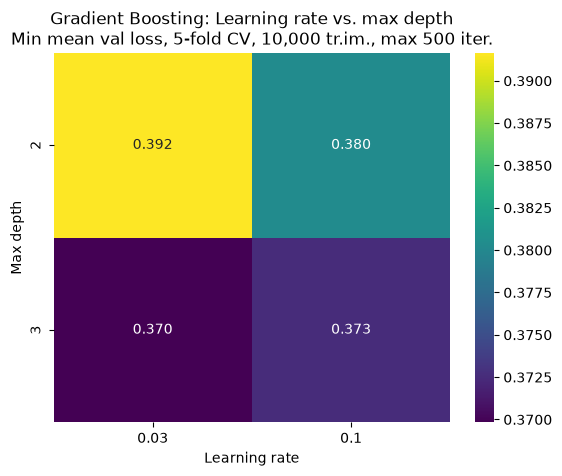

In [3]:
plot_heatmap(
    losses_lr_depth, learning_rates, max_depths,
    "Learning rate", "Max depth",
    title="Gradient Boosting: Learning rate vs. max depth\n"
          "Min mean val loss, 5-fold CV, 10,000 tr.im., max 500 iter."
)

plt.savefig(figures_dir / "GB_CV_lr_depth.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [7]:
leaf_sizes = [10, 50]
l2_values = [0.0, 10.0]

losses_leaf_l2 = np.zeros((len(leaf_sizes), len(l2_values)))

best_reg_loss = np.inf
best_leaf, best_l2 = None, None

for i, leaf in enumerate(leaf_sizes):
    for j, l2 in enumerate(l2_values):

        print(f"\nLR={best_lr}, max_depth={best_depth}, max_leaf_nodes=None, "
            f"min_samples_leaf={leaf}, L2={l2}, max_iter=500")

        loss, best_iter = run_cv_gb(
            Xtr, ytr,
            lr=best_lr,
            max_depth=best_depth,
            max_leaf_nodes=None,
            min_samples_leaf=leaf,
            l2=l2,
            max_iter=500
        )

        losses_leaf_l2[i, j] = loss

        print(f"Leaf={leaf}, L2={l2}: "
              f"loss={loss:.4f}, best iteration={best_iter}")

        if loss < best_reg_loss:
            best_reg_loss = loss
            best_leaf = leaf
            best_l2 = l2
            best_reg_iter = best_iter

print(f"\nBest overall: leaf={best_leaf}, L2={best_l2}, "
      f"loss={best_reg_loss:.4f}, best iteration={best_reg_iter}")


LR=0.03, max_depth=3, max_leaf_nodes=None, min_samples_leaf=10, L2=0.0, max_iter=500
Iteration 10: mean val loss = 1.4235
Iteration 20: mean val loss = 1.0675
Iteration 30: mean val loss = 0.8626
Iteration 40: mean val loss = 0.7328
Iteration 50: mean val loss = 0.6481
Iteration 60: mean val loss = 0.5910
Iteration 70: mean val loss = 0.5506
Iteration 80: mean val loss = 0.5205
Iteration 90: mean val loss = 0.4966
Iteration 100: mean val loss = 0.4776
Iteration 110: mean val loss = 0.4622
Iteration 120: mean val loss = 0.4500
Iteration 130: mean val loss = 0.4392
Iteration 140: mean val loss = 0.4305
Iteration 150: mean val loss = 0.4231
Iteration 160: mean val loss = 0.4168
Iteration 170: mean val loss = 0.4115
Iteration 180: mean val loss = 0.4068
Iteration 190: mean val loss = 0.4023
Iteration 200: mean val loss = 0.3988
Iteration 210: mean val loss = 0.3955
Iteration 220: mean val loss = 0.3924
Iteration 230: mean val loss = 0.3898
Iteration 240: mean val loss = 0.3876
Iteration 2

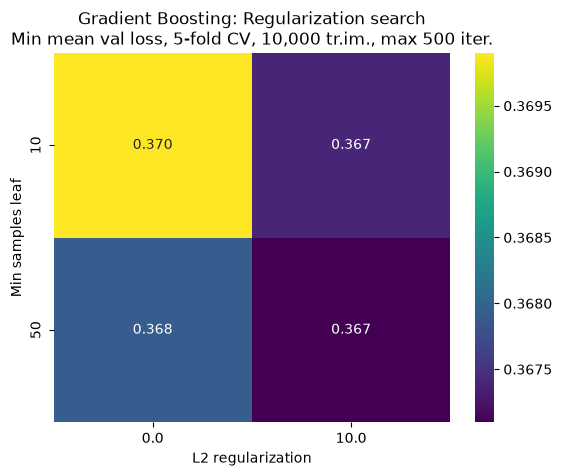

In [8]:
plot_heatmap(
    losses_leaf_l2, l2_values, leaf_sizes,
    "L2 regularization", "Min samples leaf",
    title="Gradient Boosting: Regularization search\n"
          "Min mean val loss, 5-fold CV, 10,000 tr.im., max 500 iter."
)

plt.savefig(figures_dir / "GB_CV_regularization.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [10]:
learning_rates = [0.03, 0.1]
max_depths = [5]

losses_refine = np.zeros((len(max_depths), len(learning_rates)))

best_final_loss = np.inf
best_params = None
best_final_iter = None

for i, lr in enumerate(learning_rates):
    for j, depth in enumerate(max_depths):

        print(f"\nLR={lr}, max_depth={depth}, max_leaf_nodes=None, "
              f"min_samples_leaf={best_leaf}, L2={best_l2}, max_iter=500")

        loss, best_iter = run_cv_gb(
            Xtr, ytr,
            lr=lr,
            max_depth=depth,
            max_leaf_nodes=None,
            min_samples_leaf=best_leaf,
            l2=best_l2,
            max_iter=500
        )

        losses_refine[j, i] = loss

        print(f"LR={lr}, depth={depth}: "
              f"loss={loss:.4f}, best iteration={best_iter}")

        if loss < best_final_loss:
            best_final_loss = loss
            best_final_iter = best_iter

            best_params = {
                "lr": lr,
                "max_depth": depth,
                "max_leaf_nodes": None,
                "min_samples_leaf": best_leaf,
                "l2": best_l2
            }

print(f"\nBest parameters: {best_params}")
print(f"Best iteration: {best_final_iter}")
print(f"Mean CV loss: {best_final_loss:.4f}")


LR=0.03, max_depth=5, max_leaf_nodes=None, min_samples_leaf=50, L2=10.0, max_iter=500
Iteration 10: mean val loss = 1.4205
Iteration 20: mean val loss = 1.0438
Iteration 30: mean val loss = 0.8286
Iteration 40: mean val loss = 0.6962
Iteration 50: mean val loss = 0.6107
Iteration 60: mean val loss = 0.5533
Iteration 70: mean val loss = 0.5127
Iteration 80: mean val loss = 0.4837
Iteration 90: mean val loss = 0.4617
Iteration 100: mean val loss = 0.4446
Iteration 110: mean val loss = 0.4312
Iteration 120: mean val loss = 0.4206
Iteration 130: mean val loss = 0.4112
Iteration 140: mean val loss = 0.4032
Iteration 150: mean val loss = 0.3971
Iteration 160: mean val loss = 0.3919
Iteration 170: mean val loss = 0.3874
Iteration 180: mean val loss = 0.3837
Iteration 190: mean val loss = 0.3803
Iteration 200: mean val loss = 0.3775
Iteration 210: mean val loss = 0.3747
Iteration 220: mean val loss = 0.3724
Iteration 230: mean val loss = 0.3701
Iteration 240: mean val loss = 0.3682
Iteration 

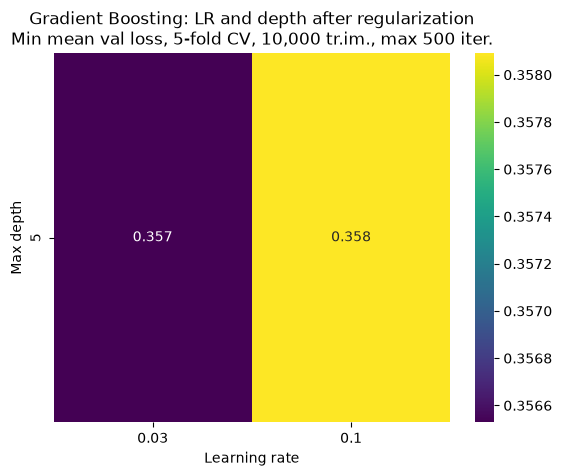

In [11]:
plot_heatmap(
    losses_refine, learning_rates, max_depths,
    "Learning rate", "Max depth",
    title="Gradient Boosting: LR and depth after regularization\n"
          "Min mean val loss, 5-fold CV, 10,000 tr.im., max 500 iter."
)

plt.savefig(figures_dir / "GB_CV_refinement.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [13]:
leaf_node_values = [15, 30]

losses_leaf_nodes = np.zeros((1, len(leaf_node_values)))
base_params = best_params.copy()

for i, max_leaves in enumerate(leaf_node_values):

    loss, best_iter = run_cv_gb(
        Xtr, ytr,
        lr=base_params["lr"],
        max_depth=None,
        max_leaf_nodes=max_leaves,
        min_samples_leaf=base_params["min_samples_leaf"],
        l2=base_params["l2"],
        max_iter=500
    )

    losses_leaf_nodes[0, i] = loss

    print(f"Max leaves={max_leaves}: "
          f"loss={loss:.4f}, best iteration={best_iter}")

    if loss < best_final_loss:
        best_final_loss = loss
        best_final_iter = best_iter

        best_params = {
            **base_params,
            "max_depth": None,
            "max_leaf_nodes": max_leaves
        }

print(f"\nBest parameters: {best_params}")
print(f"Best iteration: {best_final_iter}")
print(f"Mean CV loss: {best_final_loss:.4f}")

Iteration 10: mean val loss = 1.4175
Iteration 20: mean val loss = 1.0361
Iteration 30: mean val loss = 0.8172
Iteration 40: mean val loss = 0.6833
Iteration 50: mean val loss = 0.5980
Iteration 60: mean val loss = 0.5406
Iteration 70: mean val loss = 0.5009
Iteration 80: mean val loss = 0.4729
Iteration 90: mean val loss = 0.4517
Iteration 100: mean val loss = 0.4353
Iteration 110: mean val loss = 0.4225
Iteration 120: mean val loss = 0.4126
Iteration 130: mean val loss = 0.4046
Iteration 140: mean val loss = 0.3978
Iteration 150: mean val loss = 0.3921
Iteration 160: mean val loss = 0.3871
Iteration 170: mean val loss = 0.3829
Iteration 180: mean val loss = 0.3794
Iteration 190: mean val loss = 0.3764
Iteration 200: mean val loss = 0.3738
Iteration 210: mean val loss = 0.3717
Iteration 220: mean val loss = 0.3698
Iteration 230: mean val loss = 0.3679
Iteration 240: mean val loss = 0.3663
Iteration 250: mean val loss = 0.3649
Iteration 260: mean val loss = 0.3637
Iteration 270: mean v

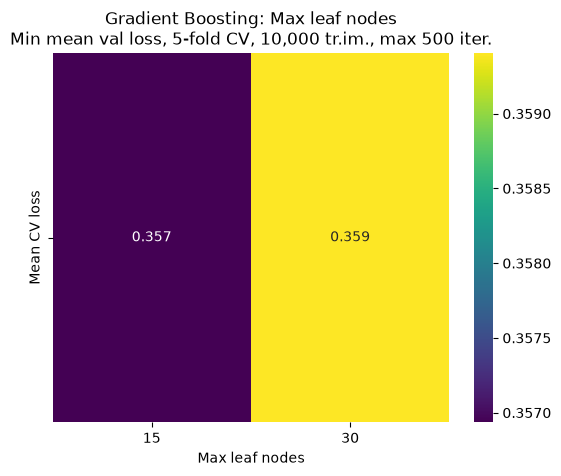

In [14]:
plot_heatmap(
    losses_leaf_nodes, leaf_node_values, ["Mean CV loss"],
    "Max leaf nodes", "",
    title="Gradient Boosting: Max leaf nodes\n"
          "Min mean val loss, 5-fold CV, 10,000 tr.im., max 500 iter."
)

plt.savefig(figures_dir / "GB_CV_max_leaf_nodes.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [15]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import fashion_mnist
from GradBoost import make_gb_model

from sklearn.metrics import (
    accuracy_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

from pathlib import Path
import time


# Best hyperparameters from CV
lr = best_params["lr"]
max_depth = best_params["max_depth"]
max_leaf_nodes = best_params["max_leaf_nodes"]
min_samples_leaf = best_params["min_samples_leaf"]
l2 = best_params["l2"]
iterations = best_final_iter

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]


# Load all 60,000 training and 10,000 test images
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Standardize using training statistics only
mean, std = x_train.mean(), x_train.std()

X_train = ((x_train - mean) / std).astype("float32").reshape(len(x_train), -1)
X_test = ((x_test - mean) / std).astype("float32").reshape(len(x_test), -1)


# Make final model
model = make_gb_model(
    lr=lr,
    max_depth=max_depth,
    max_leaf_nodes=max_leaf_nodes,
    min_samples_leaf=min_samples_leaf,
    l2=l2
)

# Set number of iterations from CV. Disable warm_start because we train the final model from scratch
model.set_params(max_iter=iterations, warm_start=False)

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.03
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",411
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",None
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",5
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",50
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",10.0
,"early_stopping early_stopping: 'auto' or bool, default='auto'If 'auto', early stopping is enabled if the sample size is larger than10000 or if `X_val` and `y_val` are passed to `fit`. If True, early stoppingis enabled, otherwise early stopping is disabled... versionadded:: 0.23",False
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",2026
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [16]:
# Train final model
start_time = time.perf_counter()

model.fit(X_train, y_train)

training_time = time.perf_counter() - start_time

Test accuracy: 0.8928 ± 0.0031
Training time: 250.30 seconds
Boosting iterations: 411
Number of trees: 4110

Per-class metrics:
              precision    recall  f1-score   support

 T-shirt/top     0.8443    0.8620    0.8530      1000
     Trouser     0.9949    0.9700    0.9823      1000
    Pullover     0.7998    0.8310    0.8151      1000
       Dress     0.8885    0.9160    0.9020      1000
        Coat     0.8132    0.8270    0.8200      1000
      Sandal     0.9877    0.9650    0.9762      1000
       Shirt     0.7187    0.6540    0.6848      1000
     Sneaker     0.9461    0.9650    0.9554      1000
         Bag     0.9721    0.9760    0.9741      1000
  Ankle boot     0.9563    0.9620    0.9591      1000

    accuracy                         0.8928     10000
   macro avg     0.8921    0.8928    0.8922     10000
weighted avg     0.8921    0.8928    0.8922     10000



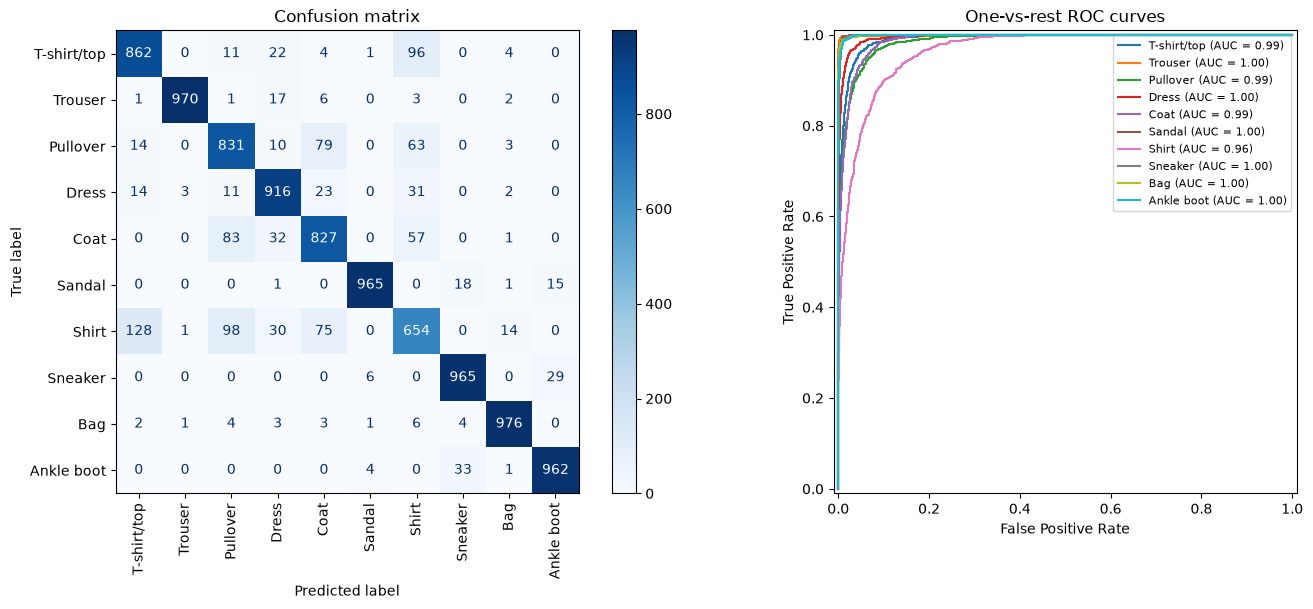

In [17]:
# Evaluate on test set ONCE
probs = model.predict_proba(X_test)
y_pred = model.predict(X_test)


# Accuracy ± standard error
acc = accuracy_score(y_test, y_pred)
se = np.sqrt(acc * (1 - acc) / len(y_test))

print(f"Test accuracy: {acc:.4f} ± {se:.4f}")
print(f"Training time: {training_time:.2f} seconds")


# Model complexity
print(f"Boosting iterations: {model.n_iter_}")
print(f"Number of trees: {model.n_trees_per_iteration_ * model.n_iter_}")


# Per-class F1 scores
print("\nPer-class metrics:")
print(classification_report(
    y_test, y_pred,
    target_names=class_names,
    digits=4
))


# Confusion matrix and one-vs-rest ROC/AUC
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=class_names,
    ax=ax[0],
    xticks_rotation=90,
    cmap="Blues"
)

ax[0].set_title("Confusion matrix")

for i, name in enumerate(class_names):
    RocCurveDisplay.from_predictions(
        (y_test == i).astype(int),
        probs[:, i],
        name=name,
        ax=ax[1]
    )

ax[1].set_title("One-vs-rest ROC curves")
ax[1].set_xlabel("False Positive Rate")
ax[1].set_ylabel("True Positive Rate")
ax[1].legend(fontsize=8)

plt.tight_layout()

plt.savefig(
    figures_dir / "GB_CV_final_results.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()